tldr; an attempt at trying to relearn my intro to quantum mechanics textbook by griffiths & schroeter from scratch.

chapter 1: the wavefunction

> schrödinger's cat walks into a bar. and doesn't.

i have a dog named java. she's a jack russell terrier and i can confirm that she's the babiest baby to ever baby. 

java ragebaits me sometimes, though. you see, her favourite game is soccer with a little tennis ball (she's too tiny to play soccer with a real soccer ball) and she loves to kick her little tennis ball into any given room in our house and stare at me expectantly. 

"sister", she probably says, "bring me back my ball"

and thus, i stand at the opening of this dark room. i don't know where this tennis ball went, all i know is that it's probably there and i need to find it.

java's ball is somewhere in the room whether I know where it is or not. an electron is not quite so cooperative.

the situation java puts me in is classical physics. 

in classical physics, we might imagine that the ball has a definite position and my lack of knowledge is the only uncertainty. 

the situation an electron puts me in is quantum physics.

in quantum physics, we instead describe a particle using a wavefunction, which tells us how likely we are to find it at different positions.

i'll give the wavefunction a name: $\psi{(x)}$ (psi, pronounced "sy", it's greek!)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

hbar = m = 1.0                    # natural units, finally after weeks of astro this feels weird lol
plt.rcParams['figure.dpi'] = 110

def evolve(psi, V, x, dt, n_steps, snap_every=None):
    '''split-step fourier: phase in position space, teleport, phase in momentum space, return.'''
    N = len(x); dx = x[1]-x[0]
    k = 2*np.pi*np.fft.fftfreq(N, dx)
    expV = np.exp(-0.5j*V*dt/hbar)                # half a potential kick
    expK = np.exp(-0.5j*hbar*k**2*dt/m)           # a full kinetic drift (in momentum space)
    snaps = []
    for s in range(n_steps):
        psi = expV*psi
        psi = np.fft.ifft(expK*np.fft.fft(psi))   # the teleporter
        psi = expV*psi
        if snap_every and s % snap_every == 0:
            snaps.append(psi.copy())
    return psi, snaps

def gaussian(x, x0, sig, k0):
    '''a wave packet: position ~x0, spread sig, momentum ~ hbar*k0.'''
    g = np.exp(-(x-x0)**2/(4*sig**2) + 1j*k0*x)
    return g/np.sqrt(np.sum(np.abs(g)**2)*(x[1]-x[0]))

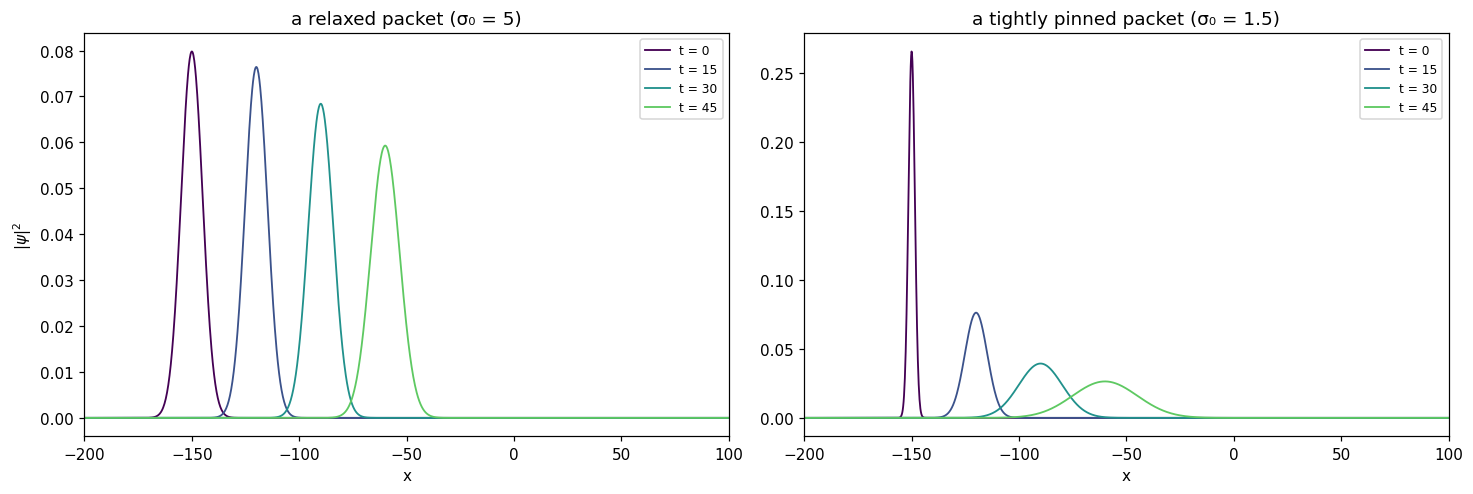

position after t=60:  measured -30.00   theory -30.00
width after t=60:     measured 7.810   theory 7.810
total probability:     1.000000000001  (unitarity: not negotiable)


In [2]:
N, L = 4096, 800.0
x = np.linspace(-L/2, L/2, N, endpoint=False)
dx = x[1]-x[0]
free = np.zeros(N)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
for ax, sig0, title in [(axes[0], 5.0, "a relaxed packet (σ₀ = 5)"),
                        (axes[1], 1.5, "a tightly pinned packet (σ₀ = 1.5)")]:
    psi = gaussian(x, -150, sig0, 2.0)
    _, snaps = evolve(psi, free, x, 0.02, 3000, snap_every=750)
    for i, s in enumerate(snaps):
        ax.plot(x, np.abs(s)**2, lw=1.2, color=plt.cm.viridis(i/len(snaps)),
                label=f"t = {i*750*0.02:.0f}")
    ax.set_xlim(-200, 100); ax.set_xlabel('x'); ax.set_title(title)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'$|\psi|^2$')
plt.tight_layout(); plt.show()

# the exam
psi = gaussian(x, -150, 5.0, 2.0)
T = 60.0
psi_f, _ = evolve(psi, free, x, 0.02, int(T/0.02))
P = np.abs(psi_f)**2; P /= P.sum()*dx
xm = (x*P).sum()*dx
sig = np.sqrt(((x-xm)**2*P).sum()*dx)
print(f"position after t={T:.0f}:  measured {xm:.2f}   theory {-150+2.0*T:.2f}")
print(f"width after t={T:.0f}:     measured {sig:.3f}   theory {5.0*np.sqrt(1+(T/(2*5.0**2))**2):.3f}")
print(f"total probability:     {np.sum(np.abs(psi_f)**2)*dx:.12f}  (unitarity: not negotiable)")